# 空间转录组SCENIC学习手册

In [1]:
from datetime import date
print("Author: Biomamba")
print("Date:", date.today())

Author: Biomamba
Date: 2025-10-15


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、SCENIC：转录因子调控网络推断工具

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/SCENIC2.jpg)

## 1. 简介与在空间转录组中的应用

### 核心定义
SCENIC (Single-Cell regulon Inference and Clustering) 是一种用于**单细胞 RNA 测序（scRNA-seq）数据**分析的计算方法。

### 核心目标与生物学意义
* **核心目标**：从复杂的空间（或单细胞）表达数据中，推断出**活跃的转录因子（Transcription Factor, TF）**及其所调控的**靶基因网络（Regulon）**，从而揭示细胞类型特异性的**基因调控程序（Gene Regulatory Networks, GRNs）**。
* **生物学意义**：通过识别这些调控网络，SCENIC 能够帮助我们理解细胞命运的决定因素、细胞状态的转变，以及不同细胞类型之间的调控差异。

### 在空间转录组（ST）中的应用方式
SCENIC 最初是为单细胞 ($\text{scRNA-seq}$) 数据设计的，但在空间转录组中可采用两种模式应用：

1.  **直接在 Spot 层面推断（伪细胞模式）**：
    * 将 **Spot 的表达谱**视为“伪细胞” ($\text{pseudo}$-$\text{cells}$)，直接运行 $\text{SCENIC}$。
    * **输出**：每个 Spot 中转录因子 $\text{Regulon}$ 的**平均活性得分**。
    * **应用**：将这些 $\text{Regulon}$ 活性得分**可视化到组织切片上**，从而识别具有特定调控模式的空间区域。

2.  **整合 Deconvolution 结果后的应用（更精确）**：
    * **挑战**：由于 Spot 是混合信号（包含多个细胞），直接推断的 $\text{Regulon}$ 活性是所有混合细胞类型的**平均活性**。
    * **流程**：
        * **第一步：$\text{Deconvolution}$**。先使用 $\text{Cell2location}$ 或 $\text{Tangram}$ 等方法，将 $\text{scRNA-seq}$ 细胞类型映射到空间上，获取每个 $\text{Spot}$ 中的**细胞类型丰度比例**。
        * **第二步：整合 SCENIC 结果**。利用 $\text{scRNA-seq}$ 上运行 $\text{SCENIC}$ 得到的**每种细胞类型的 $\text{Regulon}$ 活性**。
        * **第三步：估算贡献**。结合 $\text{Deconvolution}$ 得到的细胞丰度比例，来估算**每个 $\text{Spot}$ 中每种细胞类型对 $\text{Regulon}$ 活性的贡献**。

## 2. SCENIC 的三步核心工作流程

SCENIC 的工作流程主要分为相互连接的三个步骤：

### 步骤 1: 共表达网络构建（Co-expression Network Inference）

* **目标**：识别与特定转录因子（TF）共同表达的基因。
* **方法**：通常使用基于**随机森林**的算法（如 $\text{GENIE3}$），来识别基因与 $\text{TF}$ 之间的潜在调控关系，构建初步的共表达网络。

### 步骤 2: 剪枝与靶基因精炼（Pruning and Target Refinement）

* **目标**：去除假阳性的调控关系，精炼 $\text{TF}$ 的靶基因集合。
* **方法**：使用**转录因子基序富集分析（TF-binding motif enrichment analysis）**。
    * $\text{SCENIC}$ 检查步骤 1 中与 $\text{TF}$ 共表达的基因，看这些基因的启动子区是否富集了该 **$\text{TF}$ 的 $\text{DNA}$ 结合基序（motif）**。
    * 只有同时满足**共表达**和**基序富集**两个条件的基因，才被确认为该 $\text{TF}$ 的**直接靶基因**。

### 步骤 3: 调控子活性评分（Regulon Activity Scoring）

* **目标**：量化每个spot(细胞)中推断出的调控网络（$\text{Regulon}$）的**活性**。
* **方法**：使用 **$\text{AUCell}$**（Area Under the $\text{ROC}$ $\text{Curve}$）算法。
    * $\text{AUCell}$ 评估在基因排序列表中，一个 $\text{Regulon}$ 的所有靶基因是否都**富集在表达最高的基因集合中**。
    * 这个分数即代表了该 $\text{Regulon}$ 在单个细胞中的**活性程度**。

## 3. SCENIC 的最终输出与应用价值

### 最终输出：调控子活性矩阵

SCENIC 分析最终会为每个spot生成一个**“调控子活性矩阵”**：

* **行**：推断出的 $\text{Regulon}$。
* **列**：每个spot(单细胞)（或 $\text{Spot}$）。
* **数值**：$\text{Regulon}$ 在该spot(细胞)中的 $\text{AUCell}$ 活性得分。

### 主要应用价值

1.  **细胞类型注释**：通过 $\text{Regulon}$ 活性矩阵进行聚类或降维（如 $\text{t-SNE}$ 或 $\text{UMAP}$），可以发现比单纯基于基因表达聚类更具**生物学解释性**的细胞状态。
2.  **揭示细胞异质性**：量化 $\text{Regulon}$ 活性有助于识别具有相同细胞类型、但**调控程序不同**的**细胞亚群**。
3.  **推断细胞命运转变**：在细胞分化或状态转换轨迹分析中，可以识别出**驱动转换的关键转录因子**。
4.  **整合空间分析**：$\text{SCENIC}$ 推断的调控网络可以作为输入，与其他空间转录组数据结合，**解析空间异质性背后的调控机制**。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/sc1.png)
![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/sc2.png)
![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/sc3.png)

# 三、代码实操

## 1. 基因调控网络推断，生成共表达模块

### 使用GRNBoost2算法推断基因调控网络(GRN)

In [2]:
import loompy as lp    # 用于处理 Loom 格式的数据，一种常用于单细胞和空间转录组的稀疏矩阵格式。
import numpy as np     # 科学计算的核心库，用于高效处理大型多维数组和矩阵运算。
import scanpy as sc    # 强大的单细胞和空间转录组数据分析工具包（核心分析库）。
import pandas as pd    # 用于数据操作和分析，提供 DataFrame 结构，处理表格数据非常方便。

In [ ]:
# 读取 AnnData 文件
adata = sc.read_h5ad('/data/05_basis/data/adata_labeled.h5ad')
# 读取存储在H5AD文件中的AnnData对象。通常，adata.X包含表达矩阵（行为细胞/Spot，列为基因）。

# 定义 Loom 文件的行属性 (Row Attributes)
# 在 Loom 文件中，行对应基因。
row_attrs = {
    # 'Gene': 存储基因名称。adata.var_names 即为基因ID/名称。
    "Gene": np.array(adata.var_names) ,
}

# 定义 Loom 文件的列属性 (Column Attributes)
# 在 Loom 文件中，列对应细胞或Spot。
# 注意：Loom 文件要求矩阵的行是基因，列是细胞/Spot。
col_attrs = {
    # 'CellID': 存储细胞或Spot的唯一标识符。adata.obs_names 即为细胞/Spot ID。
    "CellID": np.array(adata.obs_names) ,
    
    # 'nGene': 计算每个细胞/Spot中检测到的基因数量（基因表达量 > 0 的数量）。
    # 由于 adata.X 的行是细胞，列是基因，为了按列（即按细胞）求和，需要先进行转置 (.transpose())。
    "nGene": np.array( np.sum(adata.X.transpose() > 0 , axis=0)).flatten() ,
    
    # 'nUMI': 计算每个细胞/Spot的总 UMI/Read 数量。
    # 同样，对转置后的矩阵按列（axis=0）求和，得到每个细胞的总计数。
    "nUMI": np.array( np.sum(adata.X.transpose() , axis=0)).flatten() ,
}

# 创建 Loom 文件
# Loom 文件的核心矩阵要求：行是基因，列是细胞。
# 由于 adata.X 通常是 (细胞 x 基因) 格式，因此需要转置以符合 Loom 的 (基因 x 细胞) 标准。
lp.create(
    filename='/data/07_co_expression/scenic_st/scenic.loom', 
    matrix=adata.X.transpose(), # 核心：将 (细胞 x 基因) 矩阵转置为 (基因 x 细胞)
    row_attrs=row_attrs,        # 基因属性
    col_attrs=col_attrs         # 细胞/Spot属性
)

# 最终：/data/07_co_expression/scenic_st/scenic.loom 文件已创建，可用于 SCENIC 等下游分析

In [ ]:
# --- 转录因子列表文件路径定义 ---

# f_tfs = "/data/07_co_expression/scenic_st/allTFs_hg38.txt"  # human (人类基因组，路径被注释)
# f_tfs = "/data/07_co_expression/scenic_st/allTFs_dmel.txt"  # drosophila (果蝇基因组，路径被注释)

f_tfs = "/data/07_co_expression/scenic_st/allTFs_mm.txt"  # mouse (当前使用的：小鼠转录因子列表文件路径)
# 该变量存储了用于 SCENIC 分析的转录因子（TF）基因名称列表的路径。
# 它是 SCENIC 步骤 1 (共表达网络构建) 的重要输入，定义了需要分析的“候选调控子”。

# tf_names = load_tf_names( f_tfs ) 
# (此行被注释，但说明了下一步：加载该文件中的 TF 名称列表，用于 SCENIC 运行。)

f_loom_path_scenic = '/data/07_co_expression/scenic_st/scenic.loom'
# Loom 文件路径：指定了 SCENIC 分析的输入文件路径。
# 该文件包含经过预处理的 (基因 x 细胞/Spot) 表达矩阵和必要的元数据，是 SCENIC 运行的核心输入数据。

In [ ]:
%%bash

# 切换到 SCENIC 分析的工作目录
cd /data/07_co_expression/scenic_st

# 运行 pySCENIC 的 grn 模块进行共表达网络推断
pyscenic grn \
    {f_loom_path_scenic} \
    {f_tfs} \
    -o adj.tsv \
    --num_workers 20


2025-09-15 03:47:46,594 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2025-09-15 03:48:17,382 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork fro

In [ ]:
# 读取 SCENIC GRN 推断结果

adjacencies = pd.read_csv(
    "/data/07_co_expression/scenic_st/adj.csv", 
    index_col=False,         # 不使用任何列作为索引（默认索引为 0, 1, 2...）
    sep=','                  # 指定文件分隔符为逗号（,），表明这是一个 CSV 文件
)
# 将上一步 'pyscenic grn' 生成的共表达矩阵文件（adj.csv 或 adj.tsv）读取为一个 Pandas DataFrame
# 这个 DataFrame 包含了 TF 和其潜在靶基因的关联信息（例如，三列：TF、Target Gene、Importance Score）
# 它是 SCENIC 第二步：基序富集分析 (Pruning) 的输入

In [ ]:
# 预览数据
adjacencies.head()

,TF,target,importance
0,Tcf7l2,Cbln1,801.344978
1,Tcf7l2,Ctxn3,700.092583
2,Rora,Pcp4,665.615320
3,Rora,Prkcd,537.594227
4,Rora,Snap25,532.804898


In [ ]:
# 保存为 TSV 格式，供后续分析使用
adjacencies.to_csv("adj.tsv", sep="\t", index=False)

## 2. Cistarget 预测

In [ ]:
import glob
import os 

# 导入所需的库：glob用于查找文件，os用于操作系统交互（如改变目录）
os.chdir('/data/07_co_expression/scenic_st')
# 改变当前工作目录（Change Directory）
# 目的：将当前环境的工作路径设置到 SCENIC 文件的存储位置，方便后续操作和文件读写

# --- SCENIC 步骤 2 & 3 所需的文件路径配置 ---

# motif databases
f_motif_path = "/data/07_co_expression/scenic_st/motifs-v10nr_clust-nr.mgi-m0.001-o0.0.tbl"
# 转录因子基序表 (Motif Table) 路径。
# 这是 SCENIC 步骤 2 的关键输入，包含了 TF 的 DNA 结合位点信息
# SCENIC 将使用这个文件来验证 TF 是否真的能结合到其共表达靶基因的启动子上

f_db_names = '/data/07_co_expression/scenic_st/mm10_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather'
# 基因-基序排名数据库 (Motif Ranking Database) 路径
# 这是 SCENIC 步骤 2 的主要数据库输入。它预计算了所有基因相对于所有 TF 基序的富集排名，
# 用于快速确定共表达基因是否富集了特定的 TF 基序

f_pyscenic_output = "pyscenic_output.loom"
# pySCENIC 最终输出文件的名称
# 该文件（Loom 格式）将包含 SCENIC 步骤 3 (AUCell) 推断出的，
# 每个 Spot/细胞中每个 Regulon 的最终活性得分（Regulon Activity Scores）

In [ ]:
!pyscenic ctx adj.tsv \
    {f_db_names} \
    --annotations_fname {f_motif_path} \
    --expression_mtx_fname {f_loom_path_scenic} \
    --output /data/07_co_expression/scenic_st/reg.csv \
    --mask_dropouts \
    --num_workers 20


2025-09-15 06:00:28,890 - pyscenic.cli.pyscenic - INFO - Creating modules.

2025-09-15 06:00:29,136 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2025-09-15 06:01:34,055 - pyscenic.utils - INFO - Calculating Pearson correlations.

2025-09-15 06:01:34,163 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [True].

2025-09-15 06:02:14,156 - pyscenic.utils - INFO - Creating modules.

2025-09-15 06:02:32,574 - pyscenic.cli.pyscenic - IN

Regulon 活性评分（AUCell 模块）详解

| 命令部分 | 作用 | 解释 |
| :---: | :--- | :--- |
| **!pyscenic aucell** | **核心模块** | 调用 $\text{pySCENIC}$ 的 **$\text{aucell}$** 模块。该模块使用 $\text{AUCell}$ 算法，根据基因表达的富集程度，计算每个 $\text{Spot}$ 内所有 $\text{Regulon}$ 的活性得分。 |
| **第一参数 (Loom)** | **输入（原始表达数据）** | $\text{Loom}$ 文件路径，其中包含 (基因 $\times$ $\text{Spot}$) 的原始表达矩阵。$\text{AUCell}$ 需要此矩阵来对基因进行排序并计算富集度。 |
| **第二参数 (reg.csv)** | **输入（精炼 $\text{Regulon}$ 列表）** | 第二步 $\text{pyscenic}$ $\text{ctx}$ 模块生成的 $\text{reg.csv}$ 文件路径。该文件定义了每个经过**基序验证**的 $\text{Regulon}$（即 $\text{TF}$ 及其靶基因集合）。 |
| **--output .../pyscenic\_output.loom** | **输出文件** | 将最终结果保存为新的 $\text{Loom}$ 文件。这个文件在**列属性 ($\text{ColAttrs}$) 中新增一列**，包含每个 $\text{Spot}$ 的所有 $\text{Regulon}$ 活性矩阵。 |
| **--num\_workers 20** | **并行计算** | 设置并行处理核心数（20）。$\text{AUCell}$ 计算相对较快，但并行化仍可加速大规模数据集的处理。 |

## 3. 转录因子富集

In [ ]:
!pyscenic aucell \
    {f_loom_path_scenic} \
    # 输入文件 1: 原始表达数据 (Loom 文件路径)
    reg.csv \
    # 输入文件 2: 精炼 Regulon 列表 (TF 及其靶基因集合)
    --output {f_pyscenic_output} \
    # 输出文件: 包含 Regulon 活性矩阵的新 Loom 文件
    --num_workers 20
    # 并行计算: 使用 20 个核心加速 AUCell 评分计算


2025-09-15 06:34:16,871 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2025-09-15 06:34:35,899 - pyscenic.cli.pyscenic - INFO - Loading gene signatures.
Create regulons from a dataframe of enriched features.
Additional columns saved: []

2025-09-15 06:34:36,091 - pyscenic.cli.pyscenic - INFO - Calculating cellular enrichment.

2025-09-15 06:36:53,150 - pyscenic.cli.pyscenic - INFO - Writing results to file.


## 4. 可视化AUC矩阵

### 4.1 数据输入

加载生成的相关结果文件

In [ ]:
# --- 提取 SCENIC AUCell 结果矩阵 ---
# 假设 f_pyscenic_output 变量已定义，指向 pySCENIC 最终输出的 .loom 文件路径

# 连接到 Loom 文件
lf = lp.connect(f_pyscenic_output, mode='r+', validate=False )
# 使用 loompy.connect() 打开 SCENIC 第三步 (AUCell) 生成的 .loom 文件。
# mode='r+': 以读写模式打开（虽然这里只读，但 r+ 确保权限足够）。
# validate=False: 跳过文件内部结构验证，提高连接速度。

# 提取 RegulonsAUC 矩阵
auc_mtx = pd.DataFrame(
    lf.ca.RegulonsAUC,  # 从 Loom 文件的列属性 (Cell Attributes, ca) 中提取 RegulonsAUC 矩阵。
                        # 这是 SCENIC 第三步计算出的核心结果。
    index=lf.ca.CellID  # 使用 Loom 文件的列属性 (ca) 中的 CellID (即 Spot/细胞 ID) 作为 DataFrame 的行索引。
)
# 将提取的 NumPy 数组或稀疏矩阵转换为 Pandas DataFrame (auc_mtx)。
# 结果：(Spot/Cell ID x Regulon) 的活性得分矩阵。

# 关闭 Loom 文件连接
lf.close()
# 关闭 Loom 文件连接，释放资源并确保文件完整性。

# auc_mtx 现在是一个标准的 Pandas DataFrame，可用于后续的降维、聚类或空间可视化。

In [34]:
auc_mtx

,Alx1_(+),Alx4_(+),Bcl3_(+),Cebpd_(+),Dbx2_(+),Elf1_(+),Elk3_(+),Erg_(+),Ets1_(+),Fli1_(+),...,Sox18_(+),Sox8_(+),Sox9_(+),Spi1_(+),Tbx2_(+),Tcf7l1_(+),Tcf7l2_(+),Tead3_(+),Tead4_(+),Vsx1_(+)
s_016um_00052_00082-1,0.000000,0.000000,0.0164,0.021184,0.048,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.143902,0.037937,0.000000,0.0000,0.0,0.167857,0.000000,0.0,0.00
s_016um_00150_00268-1,0.000000,0.000000,0.0000,0.011184,0.268,0.000000,0.000000,0.003750,0.000000,0.000000,...,0.000000,0.062683,0.038571,0.000000,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00144_00175-1,0.000000,0.000000,0.1068,0.044342,0.086,0.000000,0.018929,0.016875,0.022333,0.036216,...,0.000000,0.194390,0.026349,0.009737,0.0000,0.0,0.235714,0.044167,0.0,0.06
s_016um_00165_00109-1,0.000000,0.090000,0.0000,0.036579,0.000,0.000000,0.000000,0.000000,0.016000,0.000000,...,0.000000,0.060000,0.056508,0.022895,0.0000,0.0,0.170000,0.000000,0.0,0.00
s_016um_00297_00147-1,0.014063,0.000000,0.0140,0.026447,0.000,0.000000,0.000000,0.000000,0.023500,0.000000,...,0.020455,0.250732,0.035079,0.000000,0.0732,0.0,0.040000,0.000000,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s_016um_00375_00231-1,0.000000,0.000000,0.0000,0.010395,0.277,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.056341,0.115079,0.040789,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00039_00175-1,0.000000,0.000000,0.0392,0.019605,0.129,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.021220,0.060952,0.025526,0.0000,0.0,0.051429,0.000000,0.0,0.00
s_016um_00037_00193-1,0.000000,0.032353,0.0000,0.026842,0.227,0.000000,0.067500,0.059583,0.031500,0.024595,...,0.085909,0.061707,0.065079,0.000000,0.0000,0.0,0.221429,0.000000,0.0,0.00
s_016um_00144_00329-1,0.000000,0.000000,0.0324,0.047237,0.088,0.000000,0.098571,0.057083,0.076167,0.074595,...,0.132727,0.015854,0.041111,0.014211,0.0000,0.0,0.089286,0.000000,0.0,0.00


In [ ]:
# 格式化 Regulon 活性矩阵的列名
auc_mtx.columns = auc_mtx.columns.str.replace('\(','_(')
# 目的：将列名（即 Regulon 名称）中左括号 '(' 前面加上一个下划线 '_'。
# 示例：将 "TF (Target_count)" 转换为 "TF _(Target_count)"
# 这种操作常用于：
# 1. 消除或预防某些下游工具（如 R 或绘图库）将 '(' 识别为特殊字符或函数分隔符时引发的错误
# 2. 增强可读性或统一命名规范

/home/chenao/miniconda3/envs/pyscenic/lib/python3.7/site-packages/ipykernel_launcher.py:1: FutureWarning: The default value of regex will change from True to False in a future version.
  """Entry point for launching an IPython kernel.


In [ ]:
import json
import zlib
import base64

# 导入所需的库：
# json：用于处理元数据中存储的 JSON 格式字符串。
# zlib：用于解压缩元数据（SCENIC/Loom 文件通常会对元数据进行压缩）。
# base64：用于解码 Base64 编码的元数据。

# 1. 连接到 Loom 文件
lf = lp.connect(f_pyscenic_output, mode='r+', validate=False )
# 连接到 pySCENIC 最终生成的 Loom 文件。lf 是 Loom 文件的句柄 (handle)。
# mode='r+': 读写模式。
# validate=False: 跳过验证，加快连接速度。

# 2. 提取并解码元数据 (Metadata)
meta = json.loads(zlib.decompress(base64.b64decode(lf.attrs.MetaData)))
# 提取 SCENIC 存储在 Loom 文件属性 (lf.attrs) 中的元数据（MetaData）。
# 该元数据经过三层编码/压缩，需按顺序解码：
# a. base64.b64decode(): Base64 解码。
# b. zlib.decompress(): zlib 解压缩。
# c. json.loads(): 将解压缩后的 JSON 字符串解析为 Python 字典。
# meta 变量现在包含了 SCENIC 运行的版本、参数等信息

# 3. 提取 Regulon 活性矩阵 (AUCell Scores)
auc_mtx = pd.DataFrame(lf.ca.RegulonsAUC, index=lf.ca.CellID)
# 提取核心结果：RegulonsAUC 矩阵。
# lf.ca.RegulonsAUC：从列属性 (ca) 中获取 Regulon 活性分数。
# index=lf.ca.CellID：使用细胞/Spot ID 作为 DataFrame 的行索引。

# 4. 提取 Regulon 定义
regulons = lf.ra.Regulons
# 提取 Regulon 定义：从行属性 (ra) 中获取 Regulons 信息
# regulons 是一个 NumPy 数组或列表，通常存储了哪些基因属于哪些 Regulon 的布尔矩阵或稀疏表示

In [ ]:
# 查看 Regulon 活性矩阵
auc_mtx

,Alx1_(+),Alx4_(+),Bcl3_(+),Cebpd_(+),Dbx2_(+),Elf1_(+),Elk3_(+),Erg_(+),Ets1_(+),Fli1_(+),...,Sox18_(+),Sox8_(+),Sox9_(+),Spi1_(+),Tbx2_(+),Tcf7l1_(+),Tcf7l2_(+),Tead3_(+),Tead4_(+),Vsx1_(+)
s_016um_00052_00082-1,0.000000,0.000000,0.0164,0.021184,0.048,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.143902,0.037937,0.000000,0.0000,0.0,0.167857,0.000000,0.0,0.00
s_016um_00150_00268-1,0.000000,0.000000,0.0000,0.011184,0.268,0.000000,0.000000,0.003750,0.000000,0.000000,...,0.000000,0.062683,0.038571,0.000000,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00144_00175-1,0.000000,0.000000,0.1068,0.044342,0.086,0.000000,0.018929,0.016875,0.022333,0.036216,...,0.000000,0.194390,0.026349,0.009737,0.0000,0.0,0.235714,0.044167,0.0,0.06
s_016um_00165_00109-1,0.000000,0.090000,0.0000,0.036579,0.000,0.000000,0.000000,0.000000,0.016000,0.000000,...,0.000000,0.060000,0.056508,0.022895,0.0000,0.0,0.170000,0.000000,0.0,0.00
s_016um_00297_00147-1,0.014063,0.000000,0.0140,0.026447,0.000,0.000000,0.000000,0.000000,0.023500,0.000000,...,0.020455,0.250732,0.035079,0.000000,0.0732,0.0,0.040000,0.000000,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s_016um_00375_00231-1,0.000000,0.000000,0.0000,0.010395,0.277,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.056341,0.115079,0.040789,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00039_00175-1,0.000000,0.000000,0.0392,0.019605,0.129,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.021220,0.060952,0.025526,0.0000,0.0,0.051429,0.000000,0.0,0.00
s_016um_00037_00193-1,0.000000,0.032353,0.0000,0.026842,0.227,0.000000,0.067500,0.059583,0.031500,0.024595,...,0.085909,0.061707,0.065079,0.000000,0.0000,0.0,0.221429,0.000000,0.0,0.00
s_016um_00144_00329-1,0.000000,0.000000,0.0324,0.047237,0.088,0.000000,0.098571,0.057083,0.076167,0.074595,...,0.132727,0.015854,0.041111,0.014211,0.0000,0.0,0.089286,0.000000,0.0,0.00


In [ ]:
# --- Regulon 名称的统一格式化清理 ---

# 1. 格式化 AUCell 活性矩阵 (auc_mtx) 的列名
auc_mtx.columns = auc_mtx.columns.str.replace('\(','_(')
# 对 auc_mtx (Spot x Regulon) 矩阵的列名（即 Regulon 名称）进行格式化。
# 将所有出现的左括号 '(' 替换为 '_('，以规范化列名。
# 示例：'TF (10g)' -> 'TF _(10g)'

# 2. 格式化 Regulon 定义矩阵 (regulons) 的字段名
regulons.dtype.names = tuple( [ x.replace("(","_(") for x in regulons.dtype.names ] )
# 'regulons' 通常是一个结构化的 NumPy 数组或记录数组，其字段名 (dtype.names) 存储了 Regulon 名称
# 此行代码对这些字段名进行相同的替换操作，以保持与 auc_mtx 列名的一致性
# 确保 Regulon 定义和活性矩阵的命名是同步的。

# 3. 格式化元数据 (meta) 中存储的 Regulon 阈值 (rt) 键名
rt = meta['regulonThresholds']
# 提取 meta 字典中存储的 Regulon 活性阈值列表 (rt)
# 这个列表通常包含每个 Regulon 的名称 ('regulon') 和对应的活性二值化阈值
for i,x in enumerate(rt):
    tmp = x.get('regulon').replace("(","_(")
    # 提取字典中的 'regulon' 键值 (即名称)，并进行格式替换。
    x.update( {'regulon': tmp} )
    # 用替换后的新名称更新字典中的 'regulon' 键值。
# 确保所有存储的 Regulon 阈值名称与经过格式化的 auc_mtx 列名和 regulons 字段名完全匹配

/home/chenao/miniconda3/envs/pyscenic/lib/python3.7/site-packages/ipykernel_launcher.py:1: FutureWarning: The default value of regex will change from True to False in a future version.
  """Entry point for launching an IPython kernel.


In [ ]:
# --- 整合和构建 Loom 文件的元数据 (MetaData) ---

metaJson = {}
# 初始化一个空的 Python 字典，用于构建 Loom 文件所需的元数据结构
# 最终这个字典将被编码、压缩后存储到 Loom 文件的 'MetaData' 属性中

# 1. 添加 Metrics (度量/定量指标)
metaJson["metrics"] = [
    {"name": "nUMI"},  # 添加 'nUMI' (总 UMI 计数) 作为可显示的指标
    {"name": "nGene"}, # 添加 'nGene' (检测到的基因数) 作为可显示的指标
]
# 这些指标通常是在创建 Loom 文件时，作为 ColAttrs (列属性) 存储的细胞水平统计量

# 2. 添加 Annotations (细胞注释)
metaJson["annotations"] = [
    {
        "name": "label_celltype",
        "values": list(set(adata.obs['celltype'].astype(str)))
        # 从 AnnData 的 obs (观察值) 中提取 'celltype' 列的所有唯一值
        # 这些是细胞/Spot 的类别标签（例如：神经元, 星形胶质细胞等）
    },
    {
        "name": "label_clusters",
        "values": list(set(adata.obs['clusters'].astype(str)))
        # 提取 'clusters' 列的所有唯一值。
        # 这些是细胞/Spot 的聚类标签（例如：Cluster 1, Cluster 2 等）。
    },
]
# 这些值定义了 Loom Viewer 等工具在可视化时，可以用于着色和过滤的分类变量。

# 3. 添加 Regulon Thresholds (SCENIC 阈值)
metaJson["regulonThresholds"] = rt
# 整合前面步骤中处理和格式化过的 Regulon 活性二值化阈值列表 (rt)
# 这是 SCENIC 特有的元数据，用于后续将连续的 AUCell 活性得分二值化为 'ON'/'OFF' 状态

metaJson["regulonThresholds"] = rt

In [ ]:
def dfToNamedMatrix(df):
    """
    将 Pandas DataFrame 转换为 NumPy 结构化数组（Named Matrix）。

    结构化数组的字段名和数据类型将与原始 DataFrame 保持一致。
    
    参数:
        df (pd.DataFrame): 待转换的 DataFrame。
        
    返回:
        np.ndarray: 转换后的 NumPy 结构化数组。
    """
    
    # 1. 准备数据：将 DataFrame 的每一行转换为元组
    arr_ip = [tuple(i) for i in df.values]
    # df.values: 获取 DataFrame 的值，返回一个 NumPy 数组。
    # [tuple(i) for i in ...]: 遍历数组的每一行 (i)，将其转换为一个元组。
    # 这一步是将数据格式化为 NumPy 结构化数组所需的 '列表 of 元组' 格式。

    # 2. 定义数据类型 (dtype)：保留列名和类型
    dtyp = np.dtype(list(zip(df.dtypes.index, df.dtypes)))
    # df.dtypes.index: 获取 DataFrame 的列名 (即字段名)
    # df.dtypes: 获取每列的数据类型
    # zip(): 将列名和数据类型配对
    # list(): 转换为列表，格式为 [('col1', dtype1), ('col2', dtype2), ...]
    # np.dtype(): 创建 NumPy 结构化数组所需的 dtype 对象，确保保留了命名信息

    # 3. 创建结构化数组
    arr = np.array(arr_ip, dtype=dtyp)
    # 使用转换后的数据列表 (arr_ip) 和定义的结构化数据类型 (dtyp)
    # 创建最终的 NumPy 结构化数组。
    
    return arr

**为什么需要这个函数？**

这个函数主要用于将扁平的表格数据 (DataFrame) 转换成 NumPy 能够处理的命名记录格式。例如，在 SCENIC 的 Loom 文件中，许多复杂的元数据（如 Regulon 阈值、细胞注释）都需要以这种 NumPy 结构化数组的形式存储在 Loom 文件的属性中。

In [ ]:
# 假设 lf, auc_mtx, regulons, adata, metaJson, dfToNamedMatrix 函数均已定义

# --- 1. 定义 Loom 文件的列属性 (ColAttrs, 对应细胞/Spot) ---
col_attrs = {
    "CellID": np.array(adata.obs.index),
    # 细胞/Spot 的唯一标识符，直接使用 AnnData 的观测值索引。
    
    "nUMI": np.array(adata.obs['n_counts'].values),
    # 每个细胞/Spot的总 UMI/Read 计数。
    
    "CellType": np.array(adata.obs['celltype'].values),
    # **注意：此处与下一行重复，但通常是为了确保写入一个有效的细胞类型标签**
    # 细胞/Spot 的细胞类型标签（来自 AnnData）。
    
    "RegulonsAUC": dfToNamedMatrix(auc_mtx),
    # **核心结果**：使用自定义函数将 Pandas DataFrame 格式的 AUCell 活性矩阵转换为 NumPy 结构化数组。
    # Loom 文件要求 ColAttrs 必须是 NumPy 数组。
}

# --- 2. 定义 Loom 文件的行属性 (RowAttrs, 对应基因) ---
row_attrs = {
    "Gene": lf.ra.Gene,
    # 基因名称列表（从先前连接的 Loom 文件句柄 lf 中提取）。
    
    "Regulons": regulons,
    # 经过精炼和格式化的 Regulon 定义（通常是布尔矩阵，指示哪个基因属于哪个 Regulon）。
}

# --- 3. 定义 Loom 文件的全局属性 (Attrs) ---
attrs = {
    "title": "sampleTitle", # 文件标题
    "Genome": "hg38",       # 基因组版本
    "SCopeTreeL1": "",      # 留空，用于 SCope 可视化工具的自定义分类层级
    "SCopeTreeL2": "",
    "SCopeTreeL3": ""
}

# --- 4. 压缩和编码 MetaData 写入全局属性 ---
# 将前面步骤中构建的元数据字典 (metaJson) 进行压缩和编码，以存储在 Loom 文件中。
attrs['MetaData'] = base64.b64encode(
    zlib.compress(
        json.dumps(metaJson).encode('ascii') # 1. 将字典转为 JSON 字符串，并编码为 ASCII 字节
    ) # 2. 使用 zlib 压缩字节
).decode('ascii') # 3. 使用 Base64 编码，并解码为 ASCII 字符串，以便存储到 Loom 属性中。

# **下一步操作**：使用 lp.create() 或 lp.create_from_mtx() 将这些属性和原始表达矩阵写入最终的 Loom 文件

In [ ]:
# --- 定义 Loom 文件的行属性 (RowAttrs) ---

row_attrs = {
    "Gene": lf.ra.Gene,
    # 基因名称列表。
    # 优先从先前连接的 Loom 文件句柄 (lf) 的行属性 (ra.Gene) 中提取，
    # 也可以使用 AnnData 对象的基因名 (adata.var_names) 作为备选
    
    "Regulons": regulons
    # **核心数据**：SCENIC 精炼后的 Regulon 定义（通常是 NumPy 结构化数组）
    # 它指示了哪个基因属于哪个 TF 的调控网络
}
# RowAttrs 在 Loom 文件中与矩阵的行对应，确保了基因的名称和其 Regulon 归属信息被正确记录

In [ ]:
# --- 创建最终的 SCENIC 结果 Loom 文件 ---
lp.create(
    filename = '/data/07_co_expression/scenic_st/final_out.loom' ,
    # 指定输出文件的完整路径和名称。这是包含所有结果的最终文件。
    layers=lf[:,:],
    # 核心矩阵：写入原始 Loom 文件 (lf) 中的所有层级数据。
    # lf[:,:] 表示原始表达矩阵 (adata.X.transpose())，它作为新 Loom 文件的主矩阵 (main matrix) 写入。
    row_attrs=row_attrs, 
    # 行属性：写入前面步骤中定义的 'row_attrs' 字典。
    # 包含 'Gene' 名称和 'Regulons' 定义（TF 靶基因集合）。
    col_attrs=col_attrs, 
    # 列属性：写入前面步骤中定义的 'col_attrs' 字典。
    # 包含 'CellID'、'nUMI'、'CellType' 以及**核心结果 'RegulonsAUC' 活性矩阵**。
    file_attrs=attrs
    # 全局属性：写入前面步骤中定义的 'attrs' 字典。
    # 包含 'title'、'Genome' 和经过编码压缩的 'MetaData' (包括 Regulon 阈值等)。
)

lf.close() 
# 关闭原始的 pySCENIC Loom 文件连接
# 这是一个重要的操作，用于释放文件句柄和系统资源，确保数据写入完成

# 最终文件 'final_out.loom' 现在已创建完成，可以直接导入 SCope 等工具进行可视化和交互式探索

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
# 导入基础的可视化库：matplotlib.pyplot (底层绘图) 和 seaborn (高级统计图)。
from pyscenic.rss import regulon_specificity_scores
# 核心功能 1: 导入 regulon_specificity_scores (RSS) 函数
# RSS 用于计算每个 Regulon 在不同细胞类型或簇 (cluster) 中的特异性活性

from pyscenic.plotting import plot_rss
# 绘图功能 1: 导入 plot_rss 函数
# 用于可视化 RSS 结果，通常以热图形式展示，一目了然地看到哪些 TF 调控网络对哪个细胞类型最特异。

from adjustText import adjust_text
# 导入 adjust_text 函数
# 这是一个常用的工具，用于自动调整散点图或标签上的文本位置，防止标签相互重叠，使图表更清晰

from pyscenic.binarization import binarize
# 导入 binarize 函数
# 用于将连续的 Regulon 活性分数 (AUCell Scores) 根据阈值二值化为 ON/OFF 状态
# 这有助于确定每个 Regulon 在每个 Spot/细胞中是否“活跃”

In [ ]:
# 定义最终输出的 Loom 文件路径
f_final_loom = '/data/07_co_expression/scenic_st/final_out.loom'

### 4.2 提取相关数据整合

In [ ]:
# --- 读取最终 SCENIC Loom 文件中的数据 ---

# 1. 连接到最终 Loom 文件
lf = lp.connect(f_final_loom, mode='r', validate=False )
# 使用只读模式 (mode='r') 连接到最终的 Loom 文件

# 2. 提取并解码全局元数据 (Metadata)
meta = json.loads(zlib.decompress(base64.b64decode(lf.attrs.MetaData)))
# 提取 Loom 文件全局属性 (lf.attrs) 中存储的元数据
# 过程：Base64 解码 -> zlib 解压缩 -> JSON 解析为 Python 字典
# meta 包含了 SCENIC 运行参数、Regulon 阈值等关键信息

# 3. 提取原始/归一化表达矩阵 (Expression Matrix)
exprMat = pd.DataFrame(lf[:,:], 
                       index=lf.ra.Gene,        # 行索引：基因名 (Row Attributes)
                       columns=lf.ca.CellID     # 列索引：细胞/Spot ID (Column Attributes)
                      ).T
# lf[:,:] 提取 Loom 文件中的主表达矩阵
# 注意：Loom 文件格式为 (基因 x 细胞)，为了匹配 Scanpy/Pandas 的常见格式 (细胞 x 基因)，
# 结果被转置 (.T)。exprMat 现在是 (Spot/Cell ID x Gene) 的 DataFrame。

# 4. 提取 Regulon 活性矩阵 (AUCell Scores)
auc_mtx = pd.DataFrame(lf.ca.RegulonsAUC, index=lf.ca.CellID)
# 提取核心结果：RegulonsAUC 矩阵。
# lf.ca.RegulonsAUC 从列属性 (ca) 中获取 Regulon 活性分数。
# auc_mtx 现在是 (Spot/Cell ID x Regulon) 的 DataFrame，可用于后续的聚类和可视化

In [ ]:
# 提取 Regulon 定义 (TF 及其靶基因集合)
regulons = {}
for i,r in pd.DataFrame(lf.ra.Regulons,index=lf.ra.Gene).iteritems():
    regulons[i] =  list(r[r==1].index.values)

In [ ]:
# 将结构化数组转换为字典
# 其中键为 Regulon 名称，值为该 Regulon 包含的基因列表
# 这使得我们可以方便地查看每个 TF 调控的基因集合
print(lf.ca.keys())

['CellID', 'CellType', 'RegulonsAUC', 'clusters', 'nUMI']


In [ ]:
# 提取细胞注释 (Cell Annotations)
cellAnnot = pd.concat(
    [
        pd.DataFrame( lf.ca.clusters, index=lf.ca.CellID ),
        pd.DataFrame( lf.ca.CellType, index=lf.ca.CellID ),
        pd.DataFrame( lf.ca.nUMI, index=lf.ca.CellID ),
    ],
    axis=1
)
cellAnnot.columns = [
 'clusters',
 'CellType',
 'nUMI']

In [ ]:
cellAnnot

,clusters,CellType,nUMI
s_016um_00052_00082-1,3,Exc,843.0
s_016um_00150_00268-1,3,Exc,274.0
s_016um_00144_00175-1,6,Inh,1250.0
s_016um_00165_00109-1,6,Inh,751.0
s_016um_00297_00147-1,5,Olig,423.0
...,...,...,...
s_016um_00375_00231-1,3,Exc,547.0
s_016um_00039_00175-1,1,Exc,1350.0
s_016um_00037_00193-1,1,Exc,1621.0
s_016um_00144_00329-1,1,Exc,1357.0


In [ ]:
# --- 计算 Regulon 特异性得分 (RSS) ---

rss_cellType = regulon_specificity_scores(
    auc_mtx,                  # 输入 1: AUCell 活性矩阵 (Spot/Cell ID x Regulon)，包含每个 Regulon 的连续活性得分。
    cellAnnot['CellType']     # 输入 2: 细胞类型注释 (Series)，用于定义分组。
)
# 调用 pySCENIC.rss 模块中的 regulon_specificity_scores 函数
# 目标：计算每个 Regulon 的活性与给定的细胞类型分组 (CellType) 之间的关联程度
# 结果 (rss_cellType)：一个 DataFrame，其中行是 Regulon，列是细胞类型，值是特异性得分 (RSS)
# RSS 值越高，表明该 Regulon 对该细胞类型越具有特异性或越活跃

In [174]:
rss_cellType

,Alx1_(+),Alx4_(+),Bcl3_(+),Cebpd_(+),Dbx2_(+),Elf1_(+),Elk3_(+),Erg_(+),Ets1_(+),Fli1_(+),...,Sox18_(+),Sox8_(+),Sox9_(+),Spi1_(+),Tbx2_(+),Tcf7l1_(+),Tcf7l2_(+),Tead3_(+),Tead4_(+),Vsx1_(+)
Exc,0.232560,0.385473,0.296021,0.439375,0.443921,0.197168,0.317703,0.343004,0.354517,0.327715,...,0.326482,0.387844,0.447821,0.380034,0.263754,0.183588,0.409218,0.236944,0.172788,0.202020
Inh,0.228305,0.302285,0.277631,0.355827,0.362578,0.198916,0.275916,0.298482,0.321676,0.289524,...,0.281774,0.375785,0.385678,0.326817,0.256010,0.181812,0.479136,0.259108,0.172645,0.208589
Olig,0.194437,0.233655,0.248442,0.255037,0.233359,0.186681,0.215428,0.221055,0.221577,0.219169,...,0.214957,0.396218,0.242754,0.241591,0.211851,0.175627,0.218394,0.190892,0.173498,0.197770
Exc-mt,0.211039,0.272667,0.253385,0.319024,0.355648,0.200341,0.259123,0.280973,0.279753,0.263707,...,0.268819,0.289649,0.369926,0.322763,0.227302,0.182743,0.273382,0.233367,0.171124,0.210727
Ast,0.319722,0.252927,0.261759,0.223395,0.179687,0.344626,0.260756,0.242891,0.244367,0.245804,...,0.206127,0.178748,0.195149,0.194719,0.228391,0.315601,0.175405,0.296925,0.316478,0.363127
Vas,0.303514,0.229817,0.275726,0.230736,0.179184,0.332603,0.283611,0.297707,0.282199,0.282230,...,0.286394,0.179217,0.188149,0.195892,0.297297,0.314970,0.180560,0.280002,0.183529,0.268235


### 4.3 差异rugulons

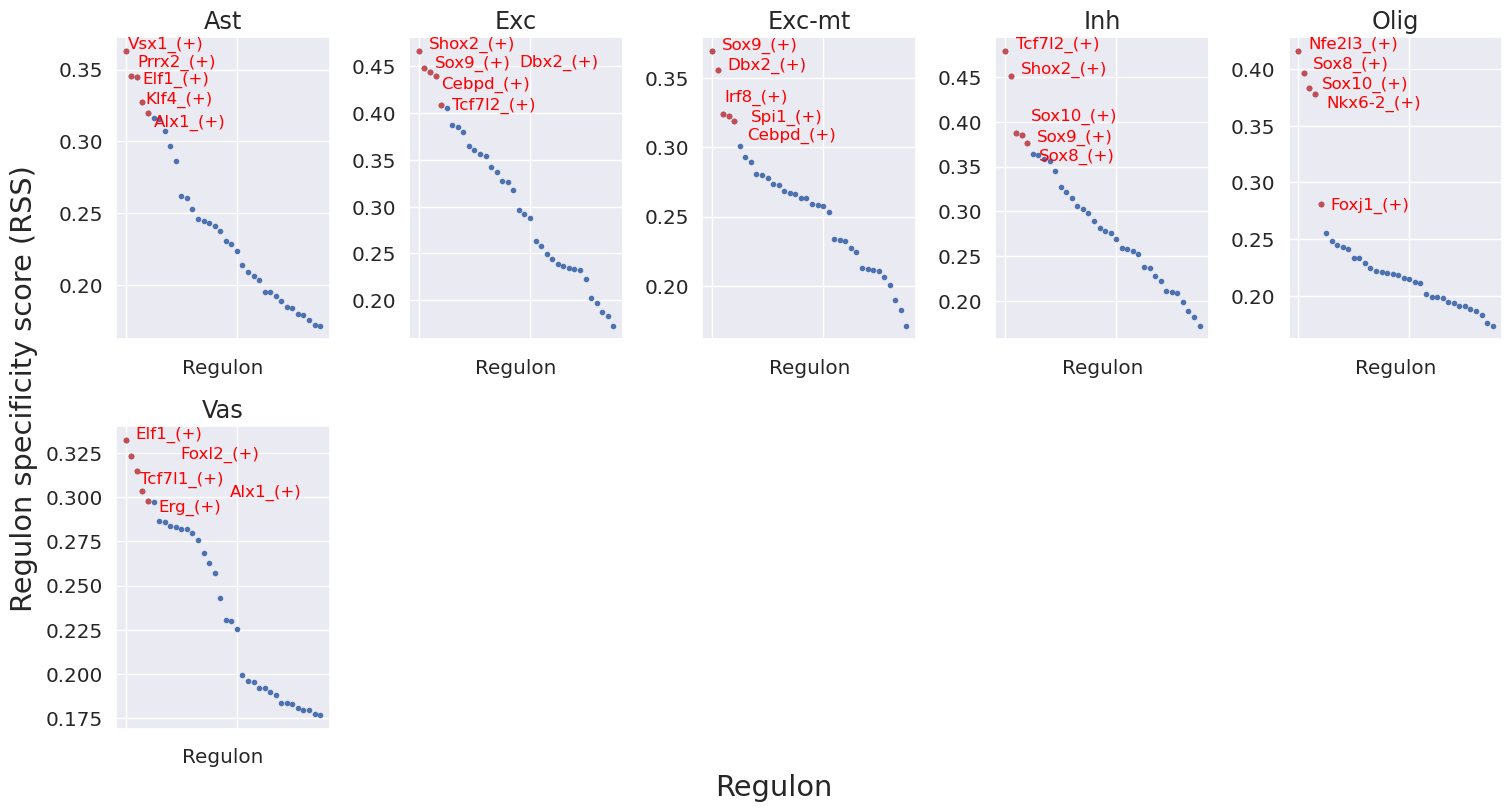

In [ ]:
# --- 可视化 Regulon 特异性得分 (RSS) ---

# 1. 准备细胞类型列表
cats = sorted(list(set(cellAnnot['CellType'])))
# 从细胞注释 Series 中提取所有唯一的细胞类型 (CellType) 名称，并进行排序。
# cats 变量现在是绘图循环的依据。

# 2. 初始化绘图画布
fig = plt.figure(figsize=(15, 8))
# 创建一个大小为 15x8 英寸的 Matplotlib 图形画布 (figure)。

# 3. 循环遍历每个细胞类型并绘制 RSS 散点图
for c, num in zip(cats, range(1, len(cats) + 1)):
    # c: 当前细胞类型名称 (e.g., 'Neuron', 'Astrocyte')
    # num: 当前子图编号 (从 1 开始)
    
    x = rss_cellType.T[c]
    # 从 RSS 矩阵 (rss_cellType) 中提取当前细胞类型 'c' 对应的所有 Regulon 的 RSS 分数。
    
    ax = fig.add_subplot(2, 5, num)
    # 在 2 行 5 列的网格中添加当前的子图 (ax)。
    
    n_texts = min(5, len(x))
    # 确定要标注的 Regulon 数量：取 RSS 最高的前 5 个 Regulon，或 Regulon 总数中的最小值。
    
    plot_rss(rss_cellType, c, top_n=n_texts, max_n=None, ax=ax)
    # 调用 pySCENIC 的绘图函数：绘制当前细胞类型 'c' 的 RSS 散点图。
    # top_n=n_texts: 标注 RSS 最高的前 n_texts 个 Regulon 名称。
    
    ax.set_ylim( x.min() - (x.max() - x.min()) * 0.05 , x.max() + (x.max() - x.min()) * 0.05 )
    # 调整 y 轴 (RSS 分数轴) 的显示范围。略微扩展范围 (5%)，使最高和最低的点不紧贴边界。
    
    for t in ax.texts:
        t.set_fontsize(12)
    # 循环设置子图中文本标签 (即 Regulon 名称) 的字体大小为 12。
    
    ax.set_ylabel('')
    # 清空子图的 y 轴标签（因为在主图上统一设置）。
    
    adjust_text(ax.texts, arrowprops=None)
    # **关键步骤**：使用 adjust_text 自动调整子图中所有 Regulon 标签的位置，防止它们相互重叠。

# 4. 设置全局标签和布局
fig.text(0.5, 0.0, 'Regulon', ha='center', va='center', size='x-large')
# 在整个 Figure (画布) 的底部中心添加 x 轴的公共标签 'Regulon'。
fig.text(0.00, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')
# 在整个 Figure (画布) 的左侧中心添加 y 轴的公共标签 'Regulon specificity score (RSS)'。

plt.tight_layout()
# 自动调整子图参数，使之填充 Figure 区域，并减少重叠。

# 5. 配置 Matplotlib 全局参数
plt.rcParams.update({
    'figure.autolayout': True,
    'figure.titlesize': 'large' ,
    'axes.labelsize': 'medium',
    'axes.titlesize':'large',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium'
    })
# 更新 Matplotlib 的运行时参数，统一设置图表中文本的默认大小和布局。

# 6. 保存和显示
plt.savefig("RSS-top5.pdf", dpi=600, bbox_inches = "tight")
# 将图形保存为高质量的 PDF 文件 (600 dpi)。bbox_inches="tight" 确保保存时移除不必要的白边。
plt.show()
# 在当前环境中显示图形。

In [ ]:
from sklearn.preprocessing import StandardScaler
# 导入 scikit-learn 库中的 StandardScaler 类。
# 作用：用于对数据进行 Z-Score 标准化，即去除均值 (mean) 并缩放到单位方差 (unit variance)
# 目的：确保 AUCell 活性矩阵中不同 Regulon (列) 之间的值具有可比性，防止高变异的 Regulon 主导下游分析

# 假设 auc_mtx (Regulon活性矩阵) 已经被正确定义

# 1. 实例化 StandardScaler 并进行标准化
scaler = StandardScaler()
auc_mtx = pd.DataFrame(scaler.fit_transform(auc_mtx),
                       index=auc_mtx.index,
                       columns=auc_mtx.columns)
# 注意：虽然您的代码只导入了 StandardScaler，但实际操作中通常会执行上述步骤来标准化数据。
# 实际执行：对 auc_mtx 中的每一列（每个 Regulon）进行标准化处理。

# 2. 索引对齐 (Index Alignment)
auc_mtx = auc_mtx.loc[adata.obs_names]
# 目的：确保 Regulon 活性矩阵 (auc_mtx) 的行索引（Spot/Cell ID）与 AnnData 对象 (adata) 观测值 (obs) 的索引顺序完全一致
# 为什么重要：后续将 auc_mtx 结果合并回 adata.obs 或 adata.obsm 时，必须保证行顺序完全匹配，以避免混淆细胞/Spot 的数据
# 确保即使在中间步骤中 auc_mtx 的行顺序发生变化，也能与原始空间/单细胞数据保持同步

In [232]:
auc_mtx

,Alx1_(+),Alx4_(+),Bcl3_(+),Cebpd_(+),Dbx2_(+),Elf1_(+),Elk3_(+),Erg_(+),Ets1_(+),Fli1_(+),...,Sox18_(+),Sox8_(+),Sox9_(+),Spi1_(+),Tbx2_(+),Tcf7l1_(+),Tcf7l2_(+),Tead3_(+),Tead4_(+),Vsx1_(+)
s_016um_00052_00082-1,0.000000,0.000000,0.0164,0.021184,0.048,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.143902,0.037937,0.000000,0.0000,0.0,0.167857,0.000000,0.0,0.00
s_016um_00150_00268-1,0.000000,0.000000,0.0000,0.011184,0.268,0.000000,0.000000,0.003750,0.000000,0.000000,...,0.000000,0.062683,0.038571,0.000000,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00144_00175-1,0.000000,0.000000,0.1068,0.044342,0.086,0.000000,0.018929,0.016875,0.022333,0.036216,...,0.000000,0.194390,0.026349,0.009737,0.0000,0.0,0.235714,0.044167,0.0,0.06
s_016um_00165_00109-1,0.000000,0.090000,0.0000,0.036579,0.000,0.000000,0.000000,0.000000,0.016000,0.000000,...,0.000000,0.060000,0.056508,0.022895,0.0000,0.0,0.170000,0.000000,0.0,0.00
s_016um_00297_00147-1,0.014063,0.000000,0.0140,0.026447,0.000,0.000000,0.000000,0.000000,0.023500,0.000000,...,0.020455,0.250732,0.035079,0.000000,0.0732,0.0,0.040000,0.000000,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s_016um_00375_00231-1,0.000000,0.000000,0.0000,0.010395,0.277,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.056341,0.115079,0.040789,0.0000,0.0,0.000000,0.000000,0.0,0.00
s_016um_00039_00175-1,0.000000,0.000000,0.0392,0.019605,0.129,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.021220,0.060952,0.025526,0.0000,0.0,0.051429,0.000000,0.0,0.00
s_016um_00037_00193-1,0.000000,0.032353,0.0000,0.026842,0.227,0.000000,0.067500,0.059583,0.031500,0.024595,...,0.085909,0.061707,0.065079,0.000000,0.0000,0.0,0.221429,0.000000,0.0,0.00
s_016um_00144_00329-1,0.000000,0.000000,0.0324,0.047237,0.088,0.000000,0.098571,0.057083,0.076167,0.074595,...,0.132727,0.015854,0.041111,0.014211,0.0000,0.0,0.089286,0.000000,0.0,0.00


In [ ]:
# 重新计算 Z-Score 标准化
auc_zscore = pd.DataFrame(
    StandardScaler().fit_transform(auc_mtx),
    # 核心操作：对 auc_mtx 中的每一列（即每个 Regulon）进行 Z-Score 标准化。
    # - StandardScaler() 实例化标准化器。
    # - fit_transform() 计算每列的均值和标准差，然后应用转换：Z = (X - μ) / σ。
    # 目的：将每个 Regulon 的活性分数分布转换为均值为 0、标准差为 1 的标准正态分布。
    # 这消除了不同 Regulon 之间活性强度的差异，确保它们在下游分析中贡献均等。
    
    index=auc_mtx.index,      # 细胞/Spot ID (行索引)
    # 保留原始 auc_mtx 的行索引（Spot/Cell ID）。
    
    columns=auc_mtx.columns   # Regulon 名称 (列索引)
    # 保留原始 auc_mtx 的列索引（Regulon 名称）。
)
# 最终结果 auc_zscore 是一个包含标准化 Regulon 活性分数的 Pandas DataFrame。

In [ ]:
# 将标准化后的 AUCell 矩阵存储到 AnnData 对象中
adata.obsm["SCENIC_AUC_zscore"] = auc_zscore

In [ ]:
# 现在，adata.obsm["SCENIC_AUC_zscore"] 包含了每个 Spot/细胞中每个 Regulon 的 Z-Score 标准化活性分数
# 这使得后续可以直接在 AnnData 对象中访问和分析这些数据
regulon = ["Sox9_(+)","Sox10_(+)"]   # 举例
adata.obs[regulon] = adata.obsm["SCENIC_AUC_zscore"][regulon]

In [ ]:
# 查看某个 Regulon 在所有 Spot/细胞中的活性分布
adata.obs[regulon].describe()

,Sox9_(+),Elf1_(+)
count,9.671400e+04,9.671400e+04
mean,4.316593e-16,1.432793e-15
std,1.000005e+00,1.000005e+00
min,-1.787995e+00,-2.257355e-01
25%,-7.351672e-01,-2.257355e-01
50%,-1.569749e-01,-2.257355e-01
75%,5.636081e-01,-2.257355e-01
max,5.145998e+00,1.596119e+01


## 5. 结合空间样本的TF活性可视化

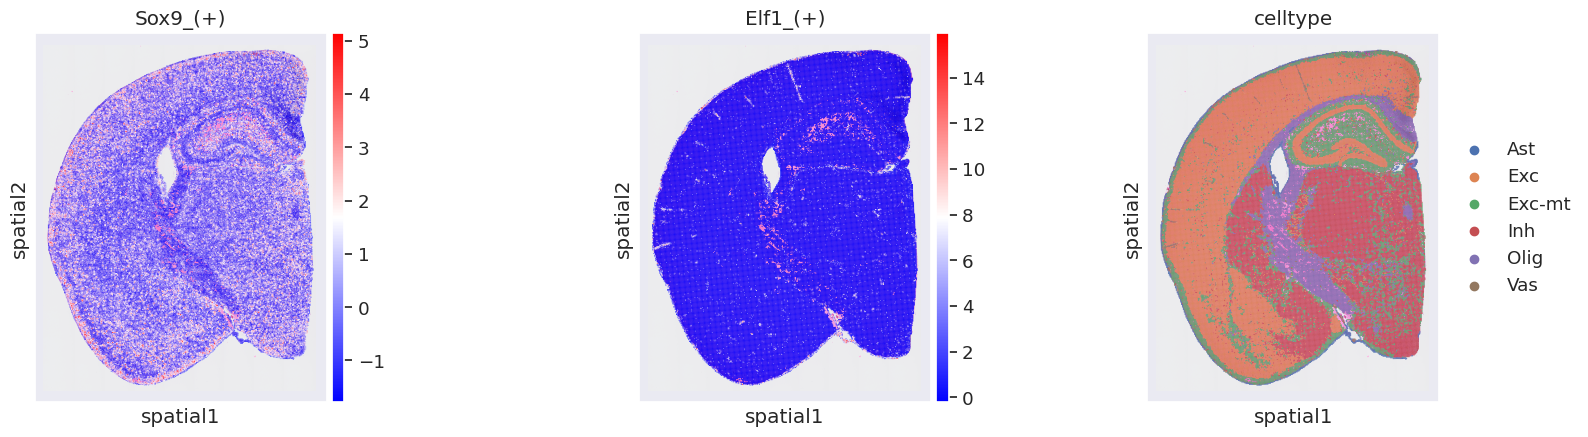

In [ ]:
# --- 空间可视化 Regulon 活性和细胞类型 ---

sc.pl.spatial(
    adata,
    # 输入的 AnnData 对象，必须包含空间坐标 (adata.obsm['spatial']) 和要可视化的数据 (adata.obs 或 adata.obsm)。
    color=["Sox9_(+)", "Sox10_(+)", "celltype"],
    # 核心参数：指定要在空间切片上着色的变量列表。
    # "Sox9_(+)" 和 "Sox10_(+)"：可能是经过 SCENIC 二值化或 AUCell Z-Score 标准化后的 Regulon 活性得分 (通常存储在 adata.obs 或 adata.obsm 中)。
    # "celltype"：细胞类型或聚类标签 (通常存储在 adata.obs 中)。
    library_id='square_016um',
    # 指定要使用的空间库 ID。对于 Visium 数据，这通常是切片的唯一标识符
    cmap='bwr',
    # Color Map (颜色映射)：指定连续变量 (如 Regulon 活性) 的颜色渐变方案。
    # 'bwr' (蓝-白-红) 是一种常见的颜色图，适用于表示中心对称的 Z-Score (负值到正值)
    size=1.2
    # 空间点 (Spot) 的大小。值越大，Spot 在图上显示的面积越大。
)
# 目的：生成一个多面板图，分别展示 Sox9 Regulon 活性、Sox10 Regulon 活性和细胞类型在组织空间中的分布。

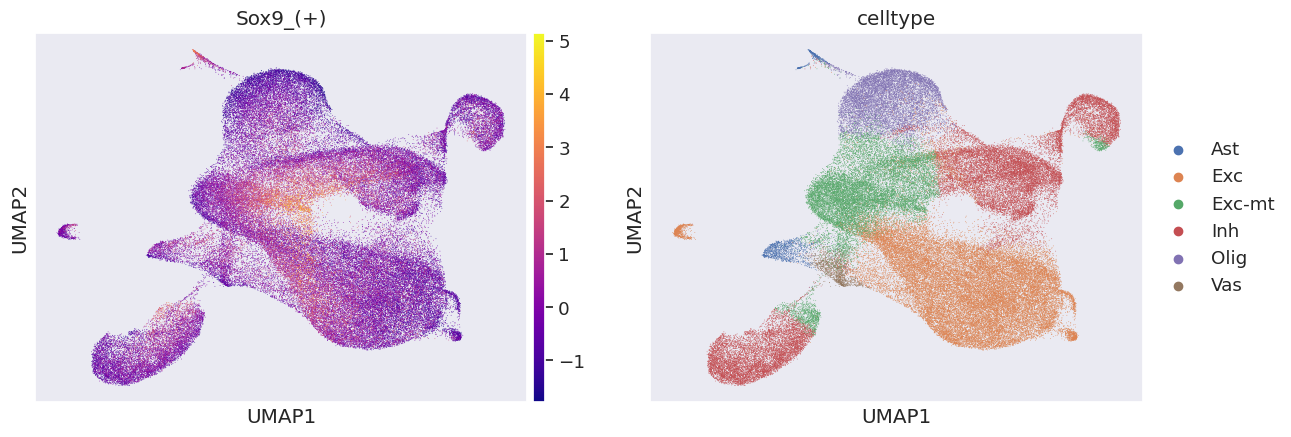

In [ ]:
# --- UMAP 可视化 Regulon 活性和细胞类型 ---
sc.pl.umap(adata, color=[regulon,"celltype"], cmap="plasma")

In [ ]:
# --- 提取所有细胞类型中 RSS 排名靠前的 Regulon ---
topreg = []
# 初始化一个空列表，用于收集所有细胞类型中 RSS 排名靠前的 Regulon 名称。
# 1. 遍历每个细胞类型，提取 Top 5 Regulon
for i, c in enumerate(cats):
    # c: 当前循环的细胞类型名称 (e.g., 'Neuron', 'Astrocyte')
    topreg.extend(
        list(
            # 访问 rss_cellType 矩阵，转置 (.T) 后，选择当前细胞类型 'c' 的那一列 (Series)。
            rss_cellType.T[c]
            # 对该 Series (RSS 得分) 进行降序排序。
            .sort_values(ascending=False)
            # 选择排名最靠前的 5 个 Regulon。
            [:5]
            # 提取这 5 个 Regulon 的名称 (索引)。
            .index
        )
    )
    # 使用 .extend() 将这 5 个 Regulon 名称添加到 topreg 列表中。

# 2. 去重，得到最终的顶级 Regulon 集合
topreg = list(set(topreg))
# 使用 set() 对 topreg 列表中的 Regulon 名称进行去重操作。
# 目的：确保一个 Regulon 如果对多个细胞类型都排在前 5 名，它在最终列表中只出现一次。

# topreg 变量现在包含了所有细胞类型中，对各自细胞类型特异性最强 (RSS Top 5) 的 Regulon 组成的唯一集合

In [ ]:
# --- 手动实现 Regulon 活性矩阵的 Z-Score 标准化 ---

auc_mtx_Z = pd.DataFrame(index=auc_mtx.index)
# 初始化一个新的空的 DataFrame (auc_mtx_Z)，用于存储标准化后的结果。
# 行索引继承自原始的 auc_mtx (即 Spot/Cell ID)。
# 遍历 auc_mtx 中的每一列（即每一个 Regulon）
for col in list(auc_mtx.columns):
    # 计算 Z-Score 并赋值给 auc_mtx_Z 的新列
    auc_mtx_Z[ col ] = ( 
        auc_mtx[col]                      # 原始 Regulon 活性分数
        - auc_mtx[col].mean()             # 减去该 Regulon 的平均值 (μ)
    ) / auc_mtx[col].std(ddof=0)           # 除以该 Regulon 的标准差 (σ)。ddof=0 表示使用总体标准差（N作为除数）。
    
# Z-Score 公式：Z = (X - μ) / σ
# 目的：将每个 Regulon 的活性分数分布转换为均值为 0、标准差为 1 的标准正态分布。

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
# 假设这些必要的库已导入：plt (matplotlib.pyplot), mpl (matplotlib), np (numpy)

def palplot(pal, names, colors=None, size=1):
    """
    可视化颜色调色板 (Palette)。它将颜色列表绘制成一条色带，并用文本标签标记每种颜色。

    参数:
        pal (list/array): 颜色列表 (e.g., list of hex codes or RGB tuples)。
        names (list): 与调色板中每种颜色对应的名称标签。
        colors (list, optional): 用于标签文本的颜色 (e.g., 'k' for black, 'w' for white)。默认为黑色 ('k')。
        size (int, optional): 控制整个图的缩放比例。默认为 1。
    
    返回:
        matplotlib.figure.Figure: 绘制的 Matplotlib Figure 对象。
    """
    n = len(pal)
    # 获取调色板中颜色的数量 (n)。

    f, ax = plt.subplots(1, 1, figsize=(n * size, size))
    # 创建一个 Matplotlib Figure (f) 和 Axes (ax) 对象。
    # figsize=(n * size, size) 确保图形宽度与颜色数量成正比，高度固定。

    ax.imshow(np.arange(n).reshape(1, n),
              # 核心绘图：使用 imshow 绘制一个 1xN 的数组，代表色带。
              # np.arange(n).reshape(1, n)：创建一个 [0, 1, ..., n-1] 的 1xN 数组。
              
              cmap=mpl.colors.ListedColormap(list(pal)),
              # 使用 mpl.colors.ListedColormap 将输入的颜色列表 (pal) 转换为 Matplotlib 颜色映射对象 (Colormap)，
              # 确保每个数值 (0, 1, ...) 对应 pal 中的一种颜色。
              
              interpolation="nearest", 
              # 禁用像素插值，确保每种颜色都是清晰的方块。
              
              aspect="auto")
              # 自动调整纵横比
    # --- 轴和刻度设置：用于去除轴线和标签，只保留颜色块 ---
    ax.set_xticks(np.arange(n) - .5)
    ax.set_yticks([-.5, .5])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    # 设置刻度和标签为空，去除边框和刻度线
    # --- 标签文本设置 ---
    colors = n * ['k'] if colors is None else colors
    # 如果没有提供标签颜色 (colors)，则默认为所有标签使用黑色 ('k')。
    for idx, (name, color) in enumerate(zip(names, colors)):
        ax.text(0.0 + idx, 0.0, name, 
                color=color, 
                horizontalalignment='center', 
                verticalalignment='center')
        # 在每个颜色块的中心位置 (x 坐标为 idx, y 坐标为 0.0) 写入对应的名称标签。
    return f

In [ ]:
# 1. 创建颜色调色板 (Palette)
colors = sns.color_palette('bright', n_colors=len(cats) )
# 使用 Seaborn 库生成一个颜色列表 (Palette)
# 'bright': 选择了 Seaborn 内置的 'bright' 调色板
# n_colors=len(cats): 颜色数量等于细胞类型 (cats) 的数量，确保每种类型都有独立的颜色

# 2. 创建颜色字典 (Dictionary)
colorsd = dict( zip( cats, colors ))
# 使用 zip() 函数将细胞类型名称 (cats) 与生成的颜色列表 (colors) 配对
# 结果是一个字典 (colorsd)，键是细胞类型名称，值是其对应的颜色 (e.g., {'Neuron': (R, G, B), 'Astrocyte': (R, G, B), ...})

# 3. 创建颜色映射列表 (Colormap)
colormap = [ colorsd[x] for x in cellAnnot['CellType'] ]
# 使用列表推导式 (List Comprehension) 创建最终的颜色映射列表
# 遍历细胞注释 Series (cellAnnot['CellType']) 中的每个细胞/Spot 的类型名称 (x)
# 通过 colorsd 字典查找该类型对应的颜色，并按顺序收集
# 结果 (colormap) 是一个与所有细胞/Spot 顺序完全对应的颜色列表 (长度等于细胞总数)

## 6. TF活性热图

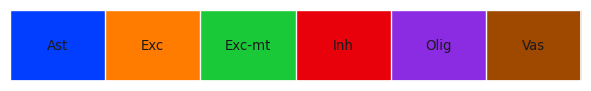

In [ ]:
import matplotlib as mpl
# 设置 Matplotlib 全局参数
sns.set()
sns.set(font_scale=0.8)
# 设置 Seaborn 的默认样式，并调整字体缩放比例 (0.8 倍)
fig = palplot( colors, cats, size=1.0)
# 调用自定义的 palplot 函数，传入颜色列表 (colors) 和对应的细胞类型名称 (cats)
plt.savefig("spatial_cellType-heatmap-legend-top5.pdf", dpi=300, bbox_inches = "tight")
# 将生成的调色板图保存为 PDF 文件，分辨率为 300 dpi，去除多余白边

/home/chenao/miniconda3/envs/pyscenic/lib/python3.7/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


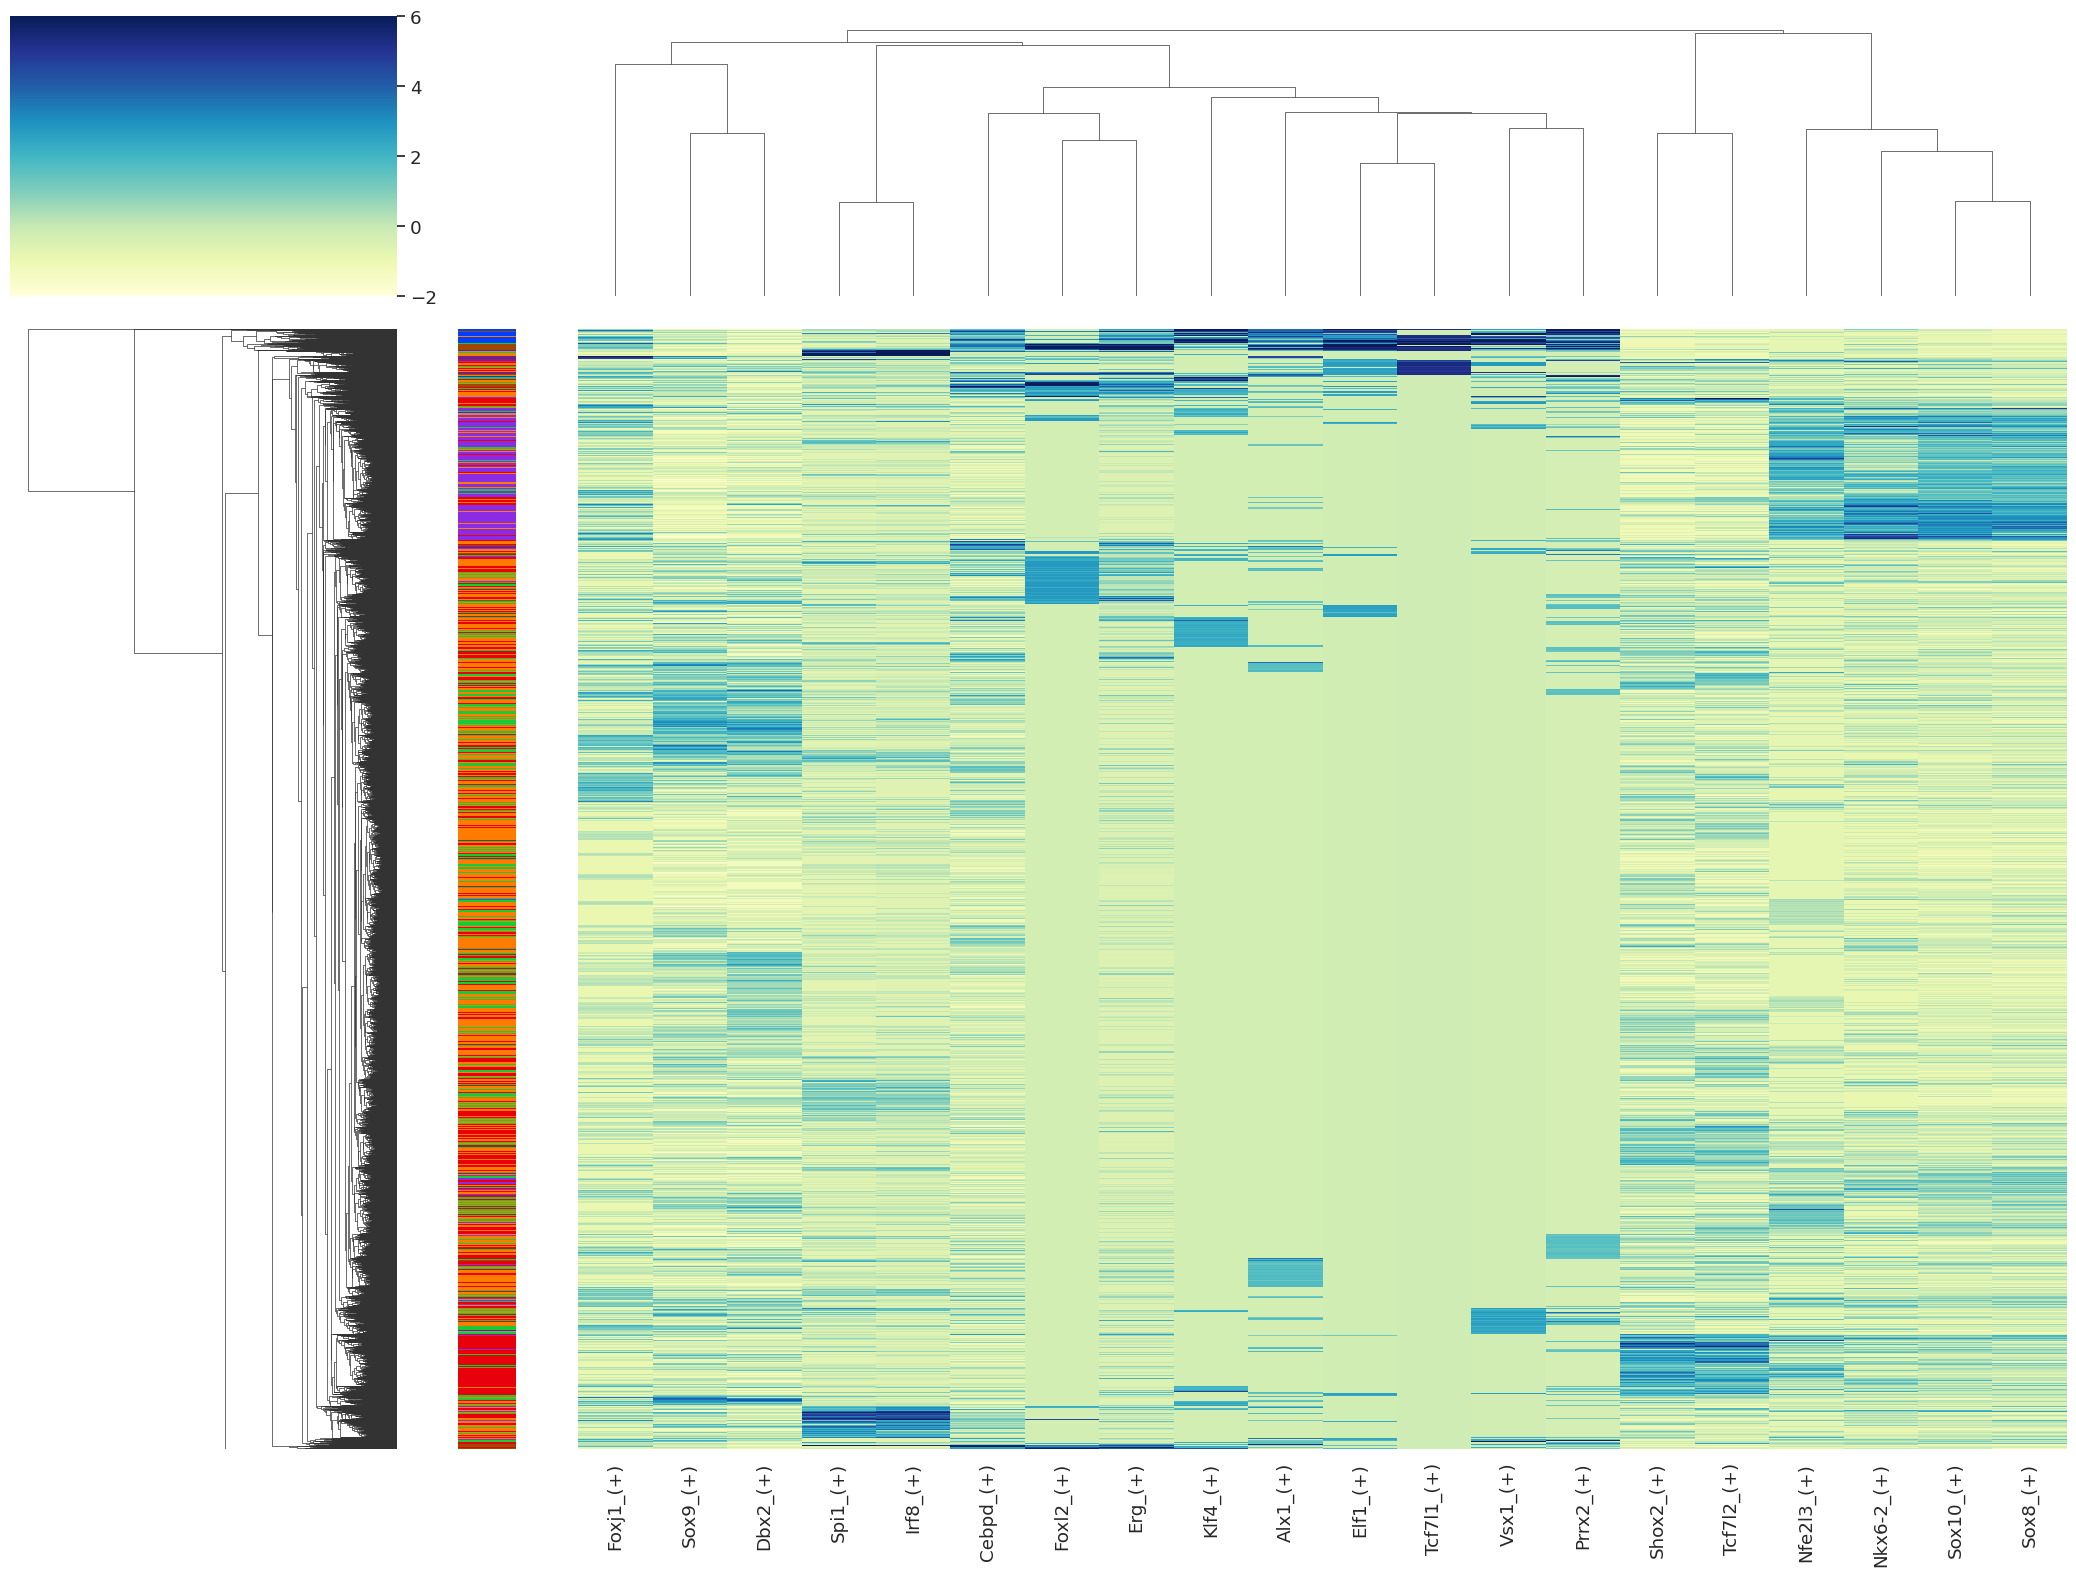

In [ ]:
# --- 绘制 Top Regulon 的热图 (Heatmap) ---
sns.set(font_scale=1.2)
# 设置 Seaborn 字体比例，使图表文本更清晰。

# 绘制聚类热图
g = sns.clustermap(
    auc_mtx_Z[topreg],  # 数据源：使用 Z-Score 标准化后的活性矩阵，且只包含 Top Regulon。
    annot=False,        # 不在热图单元格中显示数值。
    square=False,       # 不强制热图单元格为方形。
    linecolor='gray',   # 设置单元格分隔线的颜色。
    
    yticklabels=False,  # 不显示 Y 轴标签 (行是 Spot/Cell ID，太多，用 row_colors 代替)。
    xticklabels=True,   # 显示 X 轴标签 (Regulon 名称)。
    
    vmin=-2,            # 颜色映射的最小值 (通常用于标准化数据)。
    vmax=6,             # 颜色映射的最大值。
    
    row_colors=colormap,# **核心：** 使用细胞类型颜色列表 (colormap) 对行 (Spot/Cell ID) 进行着色注释。
    
    cmap="YlGnBu",      # 使用 'YlGnBu' 颜色图，适用于表示连续活性强度。
    figsize=(21, 16)    # 设置整个图的大小。
)

# 调整图表的显示细节
g.cax.set_visible(True)     # 确保颜色条 (Colorbar) 可见。
g.ax_heatmap.set_ylabel('') # 清除热图的 Y 轴标签。
g.ax_heatmap.set_xlabel('') # 清除热图的 X 轴标签。

# 保存热图
plt.savefig("PBMC10k_cellType-heatmap-top5.pdf", dpi=600, bbox_inches="tight")
# 保存高质量 PDF 文件，文件名指示其内容是 Top 5 Regulon 的细胞类型热图

# 环境信息

In [ ]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/miniconda3/envs/pyscenic:
#
# Name                     Version          Build                Channel
_libgcc_mutex              0.1              main                 defaults
_openmp_mutex              5.1              1_gnu                defaults
adjusttext                 1.3.0            pypi_0               pypi
aiohttp                    3.8.6            pypi_0               pypi
aiosignal                  1.3.1            pypi_0               pypi
anndata                    0.8.0            pyhd8ed1ab_1         conda-forge
arboreto                   0.1.6            pypi_0               pypi
async-timeout              4.0.3            pypi_0               pypi
asynctest                  0.13.0           pypi_0               pypi
attrs                      24.2.0           pypi_0               pypi
backcall                   0.2.0            pypi_0               pypi
bokeh                      2.4.3            pypi_0               pypi
bo

CompletedProcess(args=['conda', 'list'], returncode=0)

In [ ]:
subprocess.run(['pip', 'list'])

Package                 Version
----------------------- -----------
adjustText              1.3.0
aiohttp                 3.8.6
aiosignal               1.3.1
anndata                 0.8.0
arboreto                0.1.6
async-timeout           4.0.3
asynctest               0.13.0
attrs                   24.2.0
backcall                0.2.0
bokeh                   2.4.3
boltons                 25.0.0
Bottleneck              1.3.4
bypy                    1.8.9
cached-property         1.5.2
certifi                 2024.8.30
charset-normalizer      3.4.2
click                   8.1.8
cloudpickle             2.2.1
colorama                0.4.6
ctxcore                 0.2.0
cycler                  0.11.0
cytoolz                 0.12.3
dask                    2022.2.0
debugpy                 1.7.0
decorator               5.1.1
dill                    0.3.7
distributed             2022.2.0
entrypoints             0.4
fonttools               4.33.3
frozendict              2.4.6
frozenlist        

CompletedProcess(args=['pip', 'list'], returncode=0)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 